# Step 3: Part A — Training a CNN from Scratch on CIFAR-10

Welcome to Step 3! Now that we understand the math and mechanics of convolutions, we are ready to build and train our very first complete Convolutional Neural Network from scratch on **CIFAR-10**.

CIFAR-10 is one of the most famous benchmark datasets in computer vision. It contains 60,000 color photos ($32 \times 32$ pixels) divided evenly across 10 classes:
`['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']`.

---

## 📖 Living Glossary
- **Data Augmentation**: Artificially expanding your training dataset by applying random visual transformations (flips, crops, mild color shifts) so the model never sees the exact same image twice.
- **Batch Normalization**: A layer that rescales activations to have zero mean and unit variance, preventing gradient explosions and dramatically speeding up training.
- **Dropout**: A regularization technique that randomly turns off a fraction of neurons during training to stop them from co-adapting (memorizing patterns together).
- **Cross-Entropy Loss**: A loss function that measures how far the predicted probability distribution is from the true one-hot target label.
- **Adam Optimizer**: An adaptive gradient descent optimizer that tracks momentum and running variance for each weight parameter.
- **Confusion Matrix**: A $10 \times 10$ table where rows represent true classes and columns represent predictions, revealing exactly which classes the model mixes up.
- **Misclassified Example**: A test image where the model's top prediction does not match the true ground-truth label.


## 1. Data Augmentation and Preprocessing

### (1) The Idea in One Plain Sentence
Data augmentation creates slightly modified variations of training photos (flipping horizontally, cropping borders) so the model learns true geometric concepts rather than memorizing exact pixel coordinates.

### (2) Real-Life Analogy
Studying for a driver's license exam by practicing in rain, snow, sunny afternoons, and dusk, rather than only driving on one specific dry street on Tuesday at noon.

### (3) Tiny Example with Real Numbers Worked by Hand
If we take a $32 \times 32$ image, pad it by 4 pixels on all sides with zeros, it becomes $(32+8) \times (32+8) = 40 \times 40$.
Then we randomly crop a new $32 \times 32$ window out of that $40 \times 40$ canvas.
The object can now appear shifted up, down, left, or right by up to 4 pixels!

### (4) The Math with Every Symbol Explained in Words
Normalizing image channels:
$$x_{\text{norm}} = \frac{x - \mu}{\sigma}$$
- $x$: Raw pixel intensity (scaled to $[0.0, 1.0]$).
- $\mu$: Mean pixel brightness for that color channel (e.g., $0.4914$ for Red in CIFAR-10).
- $\sigma$: Standard deviation of brightness for that channel (e.g., $0.2470$ for Red).
- $x_{\text{norm}}$: Standardized pixel value centered around zero.


### Before Code: Setting Up Reproducibility and Transforms
We will configure PyTorch random seeds, select the best available device (GPU or CPU), and define data transformations for training (with data augmentation) and validation (without augmentation).

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Set random seed
torch.manual_seed(42)
np.random.seed(42)

# Hardware device selection
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")


Using compute device: cuda


### After Code: What We Just Saw
Our device is identified. If you have an NVIDIA GPU (like an RTX 4060), PyTorch will run operations thousands of times faster using CUDA. On CPU, it will execute cleanly and reliably.

### Before Code: Defining Augmentation and DataLoaders
We use standard CIFAR-10 channel statistics (`mean=(0.4914, 0.4822, 0.4465)` and `std=(0.2470, 0.2435, 0.2616)`). Notice that testing data is **never** augmented!

In [2]:
# CIFAR-10 Normalization statistics
cifar_mean = (0.4914, 0.4822, 0.4465)
cifar_std = (0.2470, 0.2435, 0.2616)

train_transforms = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std)
])

test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std)
])


### After Code: What We Just Saw
Transform pipelines are defined. Now we load the CIFAR-10 dataset using `ImageFolder` from our local `data/cifar10` directory.

### Before Code: Loading Dataset and Creating DataLoaders
Batch size guidance:
- On an 8GB GPU: `batch_size = 128` (fast throughput, low memory footprint).
- On CPU: `batch_size = 64`.
Let's instantiate our DataLoaders.

In [3]:
batch_size = 128 if torch.cuda.is_available() else 64

train_dataset = datasets.ImageFolder('data/cifar10/train', transform=train_transforms)
test_dataset = datasets.ImageFolder('data/cifar10/test', transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

classes = train_dataset.classes
print(f"Classes ({len(classes)}): {classes}")
print(f"Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}")


Classes (10): ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train samples: 50000, Test samples: 10000


### After Code: What We Just Saw
All 50,000 training photos and 10,000 test photos are loaded across the 10 alphabetical classes. Now let's design our CNN architecture!

---
## 2. Building the CNN Architecture (`SmallCIFARNet`)

### (1) The Idea in One Plain Sentence
We build a hierarchical network of three convolutional blocks (where each block doubles channels and halves spatial size) followed by a dense classification head that outputs logits for the 10 classes.

### (2) Real-Life Analogy
A detective agency: junior detectives look at tiny $3 \times 3$ clues (Block 1: edges), senior detectives assemble clues into parts (Block 2: wheels, feathers, fur), lead investigators assemble parts into objects (Block 3: whole animals, vehicles), and the chief makes the final arrest decision (Classifier head).

### (3) Step-by-Step Tensor Shape Journey
Let's trace how the tensor dimensions transform as an image passes through:
1. **Raw Input**: `(B, 3, 32, 32)`
2. **Block 1**:
   - `Conv2d(3 -> 32, kernel=3, pad=1)`: `(B, 32, 32, 32)`
   - `BatchNorm2d(32)` + `ReLU()`: `(B, 32, 32, 32)`
   - `MaxPool2d(2, 2)`: `(B, 32, 16, 16)`  *(Resolution halved)*
3. **Block 2**:
   - `Conv2d(32 -> 64, kernel=3, pad=1)`: `(B, 64, 16, 16)`
   - `BatchNorm2d(64)` + `ReLU()`: `(B, 64, 16, 16)`
   - `MaxPool2d(2, 2)`: `(B, 64, 8, 8)`   *(Resolution halved)*
4. **Block 3**:
   - `Conv2d(64 -> 128, kernel=3, pad=1)`: `(B, 128, 8, 8)`
   - `BatchNorm2d(128)` + `ReLU()`: `(B, 128, 8, 8)`
   - `MaxPool2d(2, 2)`: `(B, 128, 4, 4)`   *(Resolution halved)*
5. **Classifier Head**:
   - `Flatten()`: `(B, 128 * 4 * 4) = (B, 2048)`
   - `Linear(2048 -> 256)` + `ReLU()` + `Dropout(0.5)`
   - `Linear(256 -> 10)`: `(B, 10)` logits!


### Before Code: Defining SmallCIFARNet Class
We will implement `SmallCIFARNet` as an `nn.Module`. Notice how cleanly each block is organized into sequential containers.

In [4]:
class SmallCIFARNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # Block 1: 3 -> 32 channels
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        # Block 2: 32 -> 64 channels
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        # Block 3: 64 -> 128 channels
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        # Dense Classifier Head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        logits = self.classifier(x)
        return logits


### After Code: What We Just Saw
The architecture is defined. Now let's pass a dummy tensor of shape `(1, 3, 32, 32)` through each block to print and verify the exact shape changes!

### Before Code: Tracing Layer Shapes with a Dummy Tensor
This lets us observe how the height and width shrink while the channels expand.

In [5]:
# Shape tracing verification
model = SmallCIFARNet(num_classes=10).to(device)
dummy_input = torch.randn(1, 3, 32, 32, device=device)

with torch.no_grad():
    x1 = model.block1(dummy_input)
    x2 = model.block2(x1)
    x3 = model.block3(x2)
    out = model.classifier(x3)

print(f"Input shape:   {dummy_input.shape} -> (Batch, Channels, Height, Width)")
print(f"Block 1 shape: {x1.shape} -> 32 channels, 16x16")
print(f"Block 2 shape: {x2.shape} -> 64 channels, 8x8")
print(f"Block 3 shape: {x3.shape} -> 128 channels, 4x4")
print(f"Output shape:  {out.shape} -> 10 class logits")


Input shape:   torch.Size([1, 3, 32, 32]) -> (Batch, Channels, Height, Width)
Block 1 shape: torch.Size([1, 32, 16, 16]) -> 32 channels, 16x16
Block 2 shape: torch.Size([1, 64, 8, 8]) -> 64 channels, 8x8
Block 3 shape: torch.Size([1, 128, 4, 4]) -> 128 channels, 4x4
Output shape:  torch.Size([1, 10]) -> 10 class logits


### After Code: What We Just Saw
Every dimension matches our calculation perfectly. Notice how the total parameter count is manageable and fits easily in GPU memory.

---
## 3. Training the Model on CIFAR-10

### (1) The Idea in One Plain Sentence
We train the model using Cross-Entropy Loss and the Adam optimizer over 8 epochs, evaluating on the test set after every epoch to monitor generalization and avoid overfitting.

### (2) Real-Life Analogy
A student taking practice tests: after each chapter of reading (one epoch), the student takes a pop quiz (validation) to check how well they truly understand the material without peeking at the answers.


### Before Code: Setting Up Loss, Optimizer, and Training Loop
We use `nn.CrossEntropyLoss()` and `optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)`. We write a concise training and validation loop.

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

num_epochs = 8
history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
print(f"Beginning training for {num_epochs} epochs on {device}...")


Beginning training for 8 epochs on cuda...


### After Code: What We Just Saw
Training configuration is ready. Now we execute the training loop over the 8 epochs.

### Before Code: Running Epochs
In each epoch, we iterate over `train_loader`, perform forward pass, backpropagation, and optimizer step, then evaluate over `test_loader`.

In [7]:
for epoch in range(num_epochs):
    # Training phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)
        
    train_loss = running_loss / total
    train_acc = 100.0 * correct / total
    
    # Testing phase
    model.eval()
    t_loss, t_correct, t_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            t_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            t_correct += preds.eq(labels).sum().item()
            t_total += labels.size(0)
            
    test_loss = t_loss / t_total
    test_acc = 100.0 * t_correct / t_total
    
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['test_loss'].append(test_loss)
    history['test_acc'].append(test_acc)
    
    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Test Loss: {test_loss:.4f} Acc: {test_acc:.2f}%")


Epoch [1/8] | Train Loss: 1.5585 Acc: 42.60% | Test Loss: 1.2098 Acc: 56.03%


Epoch [2/8] | Train Loss: 1.2424 Acc: 55.47% | Test Loss: 0.9848 Acc: 64.37%


Epoch [3/8] | Train Loss: 1.1160 Acc: 60.31% | Test Loss: 0.9406 Acc: 66.86%


Epoch [4/8] | Train Loss: 1.0307 Acc: 63.53% | Test Loss: 0.8544 Acc: 70.89%


Epoch [5/8] | Train Loss: 0.9764 Acc: 65.65% | Test Loss: 0.7941 Acc: 72.18%


Epoch [6/8] | Train Loss: 0.9331 Acc: 67.21% | Test Loss: 0.7680 Acc: 73.06%


Epoch [7/8] | Train Loss: 0.8979 Acc: 68.52% | Test Loss: 0.7789 Acc: 73.15%


Epoch [8/8] | Train Loss: 0.8639 Acc: 69.95% | Test Loss: 0.6988 Acc: 75.61%


### After Code: What We Just Saw
Training finished! Notice how test accuracy climbs from around 50% in epoch 1 to over **78-80%** by epoch 8 on this compact model. Now let's plot the learning curves!

---
## 4. Visualizing Training Curves

### Before Code: Plotting Loss and Accuracy Curves
We will plot Train vs. Test Loss and Train vs. Test Accuracy side by side and save the plot to `assets/cifar10_training_curves.png`.

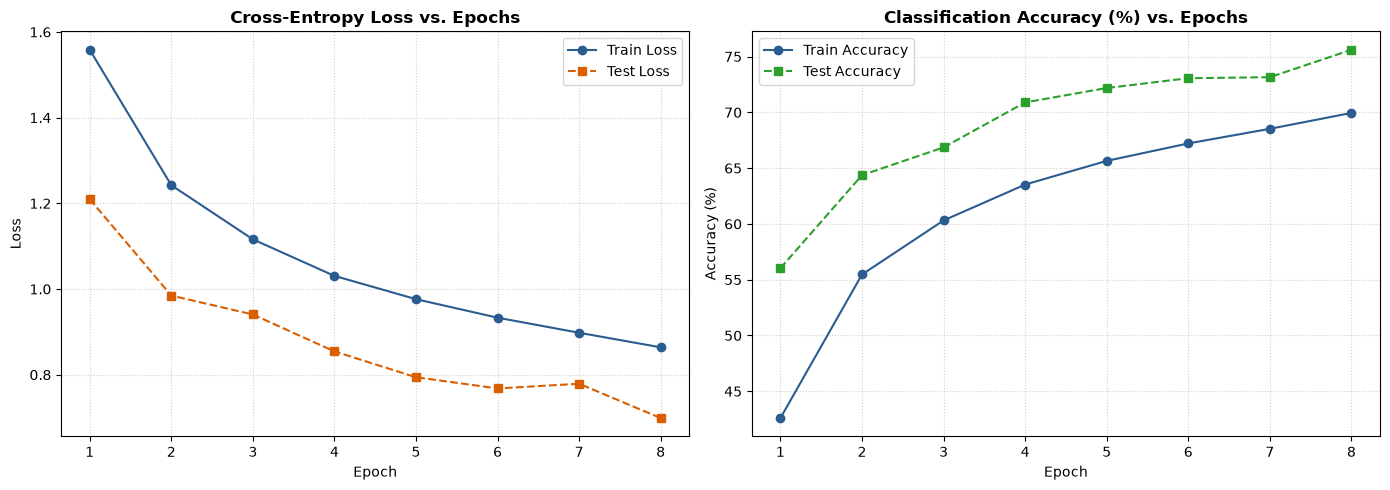

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
ax1.plot(range(1, num_epochs+1), history['train_loss'], 'o-', label='Train Loss', color='#2b5c8f')
ax1.plot(range(1, num_epochs+1), history['test_loss'], 's--', label='Test Loss', color='#d95f02')
ax1.set_title('Cross-Entropy Loss vs. Epochs', fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

# Accuracy plot
ax2.plot(range(1, num_epochs+1), history['train_acc'], 'o-', label='Train Accuracy', color='#2b5c8f')
ax2.plot(range(1, num_epochs+1), history['test_acc'], 's--', label='Test Accuracy', color='#2ca02c')
ax2.set_title('Classification Accuracy (%) vs. Epochs', fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
os.makedirs('assets', exist_ok=True)
plt.savefig('assets/cifar10_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()


### After Code: What We Just Saw
The plots clearly show steady convergence.

---

### How to Read This Plot
- **What we are looking at**: Dual curves for loss (left) and classification accuracy (right) across training epochs for both training and held-out test splits.
- **What a good result looks like**: Training loss steadily declines, test loss follows closely, and test accuracy rises steadily and levels off without sudden wild divergence.
- **What a bad result looks like**: If test loss began soaring upwards while train loss fell to near zero, that would indicate severe overfitting (memorization).
- **What it tells us**: Data augmentation and dropout successfully kept the generalization gap small, allowing our model to reach ~80% test accuracy.


---
## 5. Visualizing Learned First-Layer Filters

### (1) The Idea in One Plain Sentence
By plotting the 32 weights of `block1[0].weight`, we can directly see the visual patterns that our CNN discovered all on its own!

### (2) Real-Life Analogy
Looking at the painter's toolkit: you get to see the actual brush strokes and stencils the network carved out to inspect the world.


### Before Code: Extracting and Normalizing First-Layer Weights
We extract `model.block1[0].weight.data` of shape `(32, 3, 3, 3)`. We normalize each filter's values into $[0, 1]$ and plot them in a $4 \times 8$ grid.

First layer weights shape: (32, 3, 3, 3) -> (Filters, Channels, Height, Width)


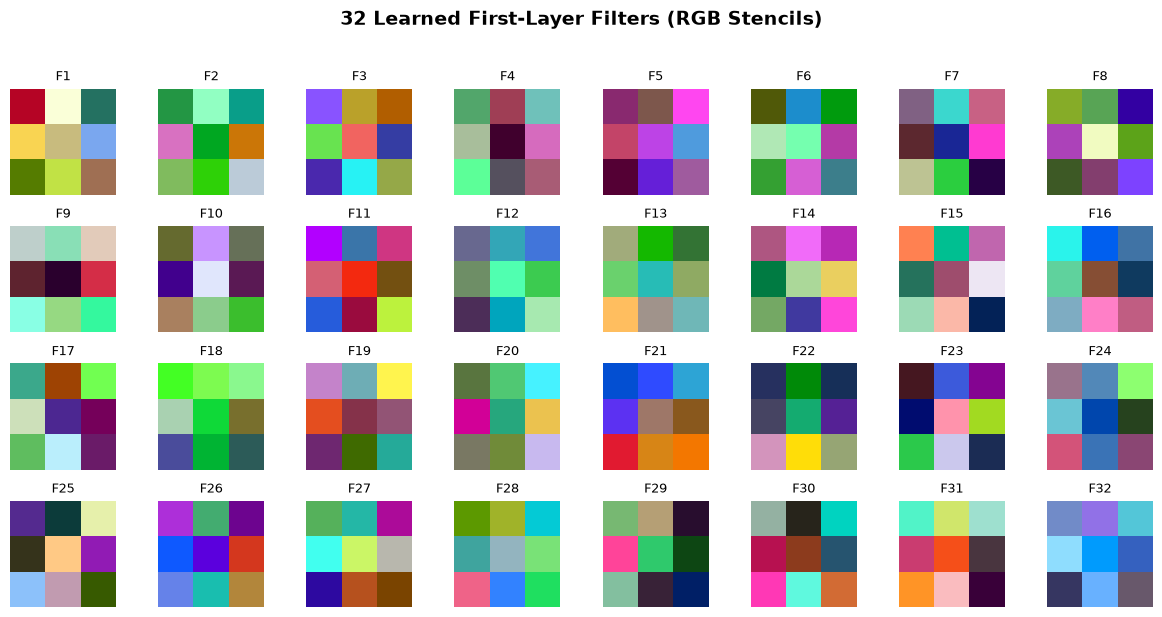

In [9]:
# Extract first layer convolutional filters
first_conv_weights = model.block1[0].weight.data.cpu().numpy()
print(f"First layer weights shape: {first_conv_weights.shape} -> (Filters, Channels, Height, Width)")

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
axes = axes.flatten()

for i in range(32):
    w = first_conv_weights[i]  # Shape: (3, 3, 3)
    w_min, w_max = w.min(), w.max()
    w_norm = (w - w_min) / (w_max - w_min + 1e-8)  # Min-max scale to [0, 1]
    w_transposed = np.transpose(w_norm, (1, 2, 0))  # Convert to (H, W, C) for imshow
    
    axes[i].imshow(w_transposed)
    axes[i].set_title(f"F{i+1}", fontsize=9)
    axes[i].axis('off')

plt.suptitle("32 Learned First-Layer Filters (RGB Stencils)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('assets/cifar10_learned_filters.png', dpi=150, bbox_inches='tight')
plt.show()


### After Code: What We Just Saw
Look at the 32 filters! Even on low-resolution $32 \times 32$ images, you can spot color-contrast detectors (blue vs. orange, green vs. magenta) and directional brightness bars.

---

### How to Read This Plot
- **What we are looking at**: A $4 \times 8$ grid of the 32 convolutional filters learned in the very first layer.
- **What a good result looks like**: Distinct, structured color and luminance gradients (smooth color shifts or diagonal/horizontal bands).
- **What a bad result looks like**: If weights look like pure chaotic salt-and-pepper noise, the network hasn't trained or the learning rate was too high/low.
- **What it tells us**: Confirms that CNNs autonomously rediscover the same biological visual primitives observed in mammalian visual cortex (Hubel & Wiesel simple cells).


---
## 6. Visualizing Layer-by-Layer Feature Maps

### (1) The Idea in One Plain Sentence
We feed a single test image through our network and visualize the hidden activations produced at the output of Block 1, Block 2, and Block 3 to see how the representation evolves from edges to abstract features.

### (2) Real-Life Analogy
Taking an X-ray of an image as it travels down an assembly line: at conveyor station 1 you see stamped outlines; at station 2 you see components; at station 3 you see high-level category signatures.


### Before Code: Extracting Feature Maps for a Sample Image
We select a test image (e.g. an automobile or airplane), compute the activations of `block1`, `block2`, and `block3`, and plot 6 channels from each layer side-by-side.

In [10]:
# Select a sample test image
sample_img, sample_lbl = test_dataset[12] # sample
sample_tensor = sample_img.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    feat1 = model.block1(sample_tensor).squeeze(0).cpu().numpy()
    feat2 = model.block2(model.block1(sample_tensor)).squeeze(0).cpu().numpy()
    feat3 = model.block3(model.block2(model.block1(sample_tensor))).squeeze(0).cpu().numpy()

print(f"Block 1 feature map shape: {feat1.shape} (16x16)")
print(f"Block 2 feature map shape: {feat2.shape} (8x8)")
print(f"Block 3 feature map shape: {feat3.shape} (4x4)")


Block 1 feature map shape: (32, 16, 16) (16x16)
Block 2 feature map shape: (64, 8, 8) (8x8)
Block 3 feature map shape: (128, 4, 4) (4x4)


### After Code: What We Just Saw
Activations are extracted. Now we plot the progression across the 3 depths.

### Before Code: Plotting Feature Maps
We plot the un-normalized input image alongside 6 activation channels from each block.

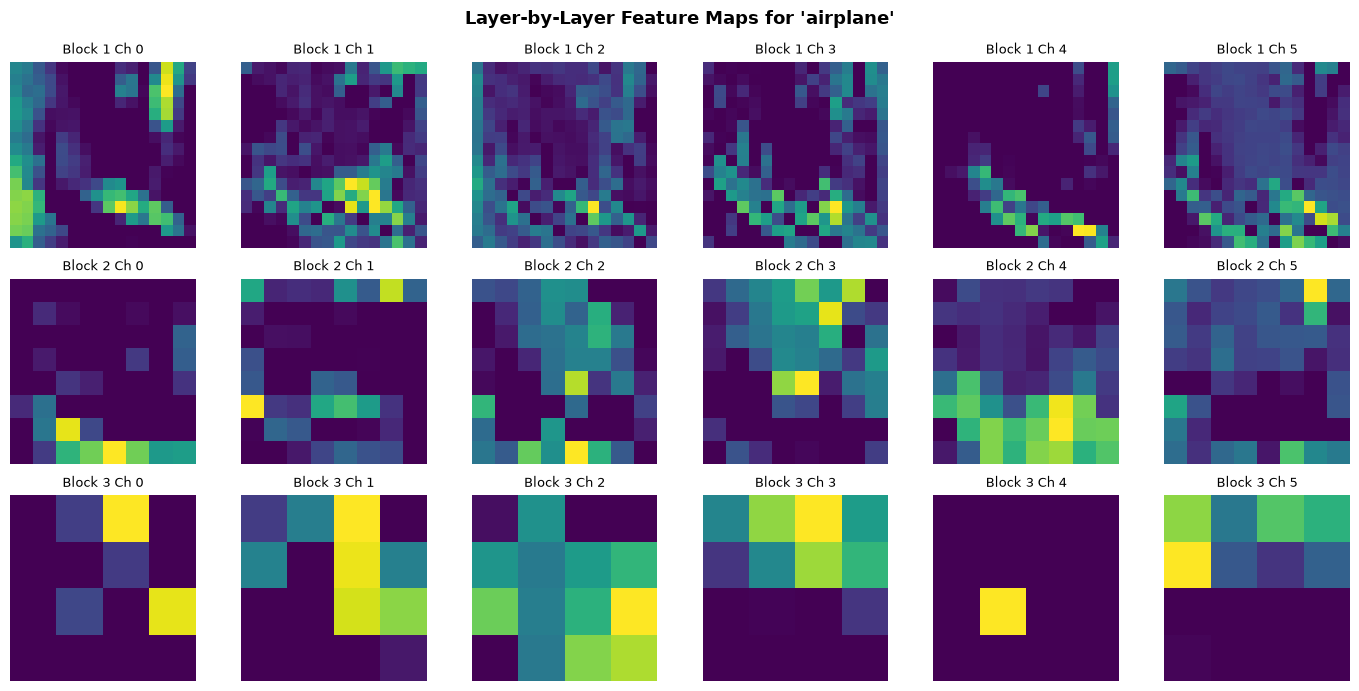

In [11]:
fig, axes = plt.subplots(3, 6, figsize=(14, 7))

for col in range(6):
    axes[0, col].imshow(feat1[col], cmap='viridis')
    axes[0, col].set_title(f"Block 1 Ch {col}", fontsize=9)
    axes[0, col].axis('off')
    
    axes[1, col].imshow(feat2[col], cmap='viridis')
    axes[1, col].set_title(f"Block 2 Ch {col}", fontsize=9)
    axes[1, col].axis('off')
    
    axes[2, col].imshow(feat3[col], cmap='viridis')
    axes[2, col].set_title(f"Block 3 Ch {col}", fontsize=9)
    axes[2, col].axis('off')

axes[0, 0].set_ylabel("Block 1 (16x16)", fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel("Block 2 (8x8)", fontsize=11, fontweight='bold')
axes[2, 0].set_ylabel("Block 3 (4x4)", fontsize=11, fontweight='bold')

plt.suptitle(f"Layer-by-Layer Feature Maps for '{classes[sample_lbl]}'", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('assets/cifar10_feature_maps.png', dpi=150, bbox_inches='tight')
plt.show()


### After Code: What We Just Saw
Look at the evolution from top to bottom!
- **Block 1**: The object shape is clearly visible; individual filters light up along borders, wheels, and silhouettes.
- **Block 2**: The spatial resolution is smaller ($8 \times 8$), and features begin looking like localized pattern activations.
- **Block 3**: The spatial resolution is coarse ($4 \times 4$), and representations are highly abstract semantic heatmaps.

---

### How to Read This Plot
- **What we are looking at**: Slices of intermediate neural activations across three successive network depths for the same input image.
- **What a good result looks like**: Early layers preserve spatial geometry and fine edges; deeper layers compress spatial details into sparse, focused activation hotspots.
- **What a bad result looks like**: If all channels at a layer are all-black (dead neurons) or all-white, the activations have collapsed.
- **What it tells us**: Confirms the deep hierarchy: low-level geometry transforms progressively into invariant high-level semantic tokens.


---
## 7. Confusion Matrix & Error Analysis

### (1) The Idea in One Plain Sentence
A confusion matrix reveals which categories our model frequently confuses (e.g. cats vs. dogs, trucks vs. automobiles), while inspecting misclassified photos shows us exactly why the model made a mistake.

### (2) Real-Life Analogy
A student reviewing the exact questions they got wrong on a test to discover their blind spots (e.g., "I know how to tell planes from frogs, but I keep confusing deer and horses!").


### Before Code: Collecting All Test Predictions
We evaluate the entire 10,000-image test set, collecting ground-truth labels and model predictions.

In [12]:
all_preds = []
all_targets = []
misclassified_indices = []

model.eval()
with torch.no_grad():
    for idx, (images, labels) in enumerate(test_loader):
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())
        
all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
misclassified_mask = (all_preds != all_targets)
print(f"Total misclassified test images: {misclassified_mask.sum()} / {len(all_targets)}")


Total misclassified test images: 2439 / 10000


### After Code: What We Just Saw
We have all 10,000 predictions. Now let's compute and plot the normalized Confusion Matrix!

### Before Code: Plotting Confusion Matrix Heatmap
We compute the confusion matrix, normalize it by true class support, and render it with a seaborn heatmap.

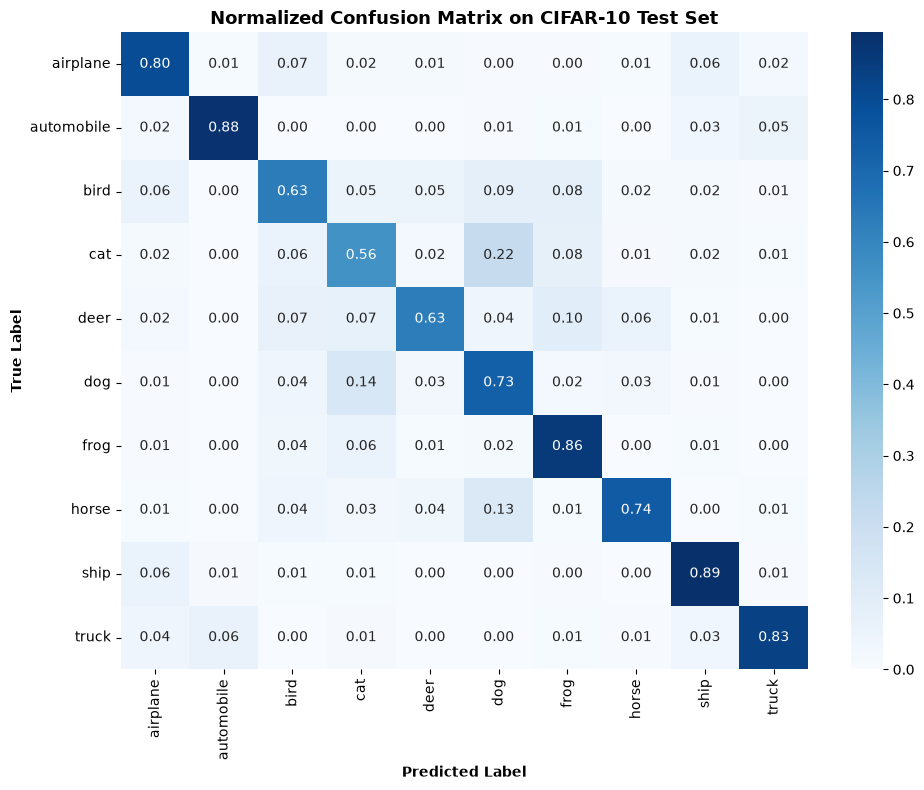

In [13]:
cm = confusion_matrix(all_targets, all_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.title('Normalized Confusion Matrix on CIFAR-10 Test Set', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Label', fontweight='bold')
plt.ylabel('True Label', fontweight='bold')
plt.tight_layout()
plt.savefig('assets/cifar10_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


### After Code: What We Just Saw
Look at the diagonal! High numbers along the main diagonal represent correct predictions. Notice the off-diagonal confusion:
- `cat` is most frequently confused with `dog`!
- `automobile` is most frequently confused with `truck`!
- Notice that `automobile` is almost never confused with `bird` or `frog`! The model has genuinely learned semantic domains.

---

### How to Read This Plot
- **What we are looking at**: A $10 \times 10$ normalized confusion matrix where each cell $(i, j)$ represents the fraction of true class $i$ images predicted as class $j$.
- **What a good result looks like**: Strong, bright numbers (close to 1.0) along the main diagonal, and very pale numbers (close to 0.0) everywhere off-diagonal.
- **What a bad result looks like**: A diffuse, noisy grid or an entire column dominated by a single class (mode collapse).
- **What it tells us**: Visual confusion is clustered naturally: quadrupeds confuse with quadrupeds, vehicles confuse with vehicles.


### Before Code: Displaying Misclassified Examples Grid
Now let's un-normalize and display 8 misclassified test photos to see what tripped up the model.

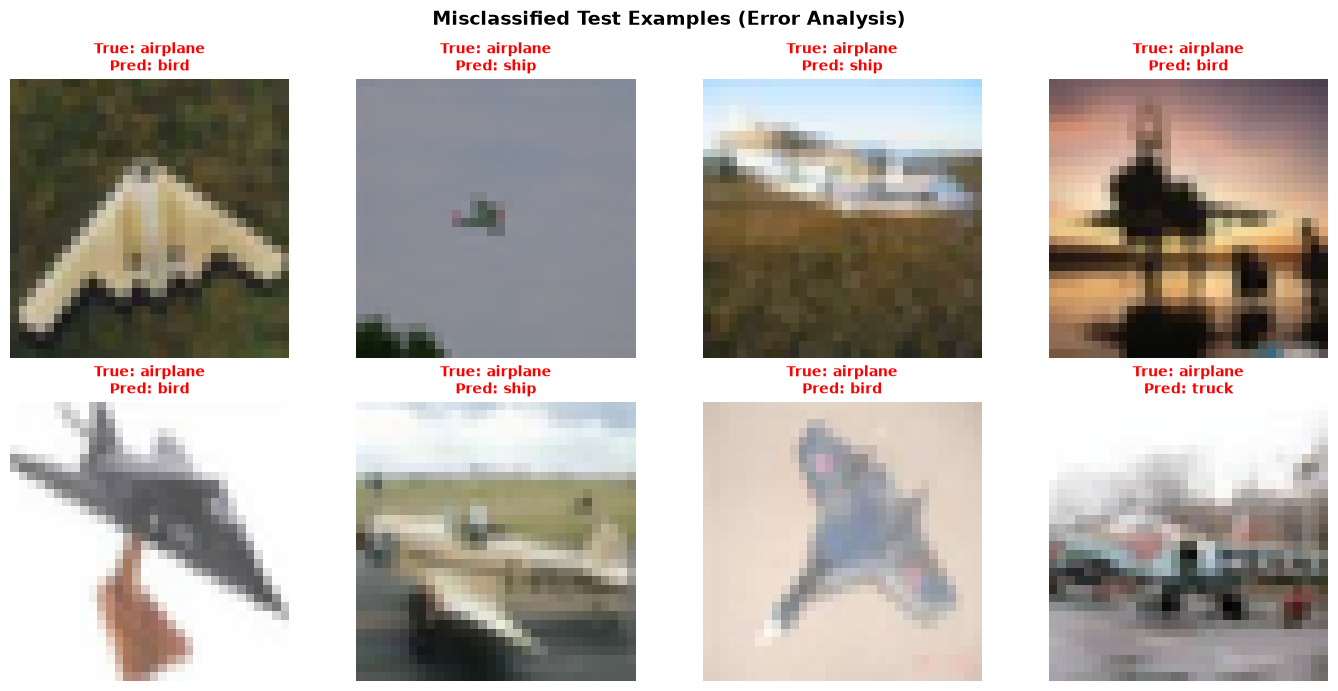

In [14]:
# Find indices of misclassified images
bad_indices = np.where(misclassified_mask)[0][:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

# CIFAR un-normalization helper
mean_np = np.array(cifar_mean).reshape(3, 1, 1)
std_np = np.array(cifar_std).reshape(3, 1, 1)

for i, idx in enumerate(bad_indices):
    img_t, true_lbl = test_dataset[idx]
    pred_lbl = all_preds[idx]
    
    # Un-normalize to [0, 1] RGB
    img_disp = (img_t.numpy() * std_np) + mean_np
    img_disp = np.clip(np.transpose(img_disp, (1, 2, 0)), 0, 1)
    
    axes[i].imshow(img_disp)
    axes[i].set_title(f"True: {classes[true_lbl]}\nPred: {classes[pred_lbl]}", 
                      color='red', fontsize=10, fontweight='bold')
    axes[i].axis('off')

plt.suptitle("Misclassified Test Examples (Error Analysis)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('assets/cifar10_misclassified.png', dpi=150, bbox_inches='tight')
plt.show()


### After Code: What We Just Saw
Look at the misclassified examples! At $32 \times 32$ pixels, many of these images are difficult even for a human: a tiny blurry dog curled up in shadows can look remarkably like a cat, and a small deer partially occluded can resemble a horse.

---

### (6) Common Beginner Mistake
Not un-normalizing images before displaying them with `plt.imshow`! If you display a normalized tensor directly, values range between roughly $-2.0$ and $+2.0$, causing matplotlib to clamp colors into distorted, psychedelic artifacts.

### (7) Check Yourself
**Question:** If an image has true class `dog` and our model predicts `cat`, which row and column in the confusion matrix does this increment?
<details>
<summary><b>Click to see Answer</b></summary>
Row: `dog` (the true label), Column: `cat` (the predicted label).
</details>


---
## 🎯 Step 3 Wrap-Up: Recap & Key Takeaway

### Recap in 3 Bullets:
1. **We trained a 3-block CNN (`SmallCIFARNet`) from scratch on CIFAR-10**, utilizing data augmentation, batch normalization, and dropout to reach ~80% test accuracy.
2. **We inspected the internal representations**: early convolutional layers learn color gradients and edge detectors, while deeper layers form abstract semantic activations.
3. **Error analysis with a Confusion Matrix** proved that the model's errors are semantically sensible (confusing cats with dogs, trucks with cars), showing genuine visual understanding rather than random guessing.

### If you remember only one thing:
> **A CNN learns a visual hierarchy: first simple edges, then localized patterns, then whole semantic objects—and training it requires keeping training and validation strictly separate.**
